# Compare the three models

**Purpose:** put K-means, Gaussian Mixture (GMM) and Hierarchical clustering on the **same footing** and say whether any of them finds reliable groups of homes.

**Why this notebook exists:** each model notebook uses its own stability test, and the GMM notebook has no shuffled-data baseline. So the scores in the three notebooks cannot be compared. Here every model gets the **same two tests**, each compared with the **same 100 shuffled datasets**.

**Run after:** `02_KMeans` (needs `home_features.csv`, `home_segments.csv`) and `03_GMM` (needs `segments_gmm.csv`). It also reads the raw data.

**Requires:** pandas, numpy, matplotlib, scikit-learn.

**How to read this notebook:** each grey box is code (the *input*). The result printed under it is the *output*. Press **Run All** to produce the outputs again. The shuffle tests take a few minutes.

**Steps:** 1 Load - 2 Define the models and tests - 3 The groups each model finds - 4 Do the models agree? - 5 Tests on real and shuffled data - 6 Charts - 7 Verdict - 8 Save the results

## Settings
- `K`: the number of groups used for each model. These are the working choices of the model notebooks: K-means 3, GMM 2 (the lowest BIC once k is at least 2), Hierarchical 3 (used only for comparison).
- `N_SHUFFLES`: how many shuffled copies of the data to test (100).
- `N_SPLITS`: how many random splits in each stability test (5).

In [1]:
import warnings                                   # to hide one kind of harmless warning
from pathlib import Path                         # a tool for working with folder paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")

DATA_DIR = Path("../data") if Path("../data").exists() else Path("../Data")   # "data", or "Data" if it is named that way
RAW_FILE = DATA_DIR / "raw" / "smart_home_energy_consumption_large.csv"
PROCESSED = DATA_DIR / "processed"

K = {"K-means": 3, "Gaussian Mixture": 2, "Hierarchical": 3}   # groups per model
MODELS = list(K)
N_SHUFFLES = 100       # shuffled copies of the data
N_SPLITS = 5           # random splits per stability test
SEED = 42              # makes every random step repeat exactly
ENERGY = "Energy Consumption (kWh)"

## Load the data
- The raw readings (needed to build shuffled copies and to split each home's readings).
- The 500 x 10 home table made by the K-means notebook, and the groups saved by the K-means and GMM notebooks.

In [2]:
df = pd.read_csv(RAW_FILE)
features = pd.read_csv(PROCESSED / "home_features.csv", index_col="Home ID")
km_saved = pd.read_csv(PROCESSED / "home_segments.csv", index_col="Home ID")["cluster"]
gmm_saved = pd.read_csv(PROCESSED / "segments_gmm.csv", index_col=0)["segment"]      # the GMM file names its first column "home"

appliance_cols = [c for c in features.columns if c not in ["n_readings", "avg_kwh"]]
print("Readings:", df.shape[0], "| homes:", features.shape[0], "| appliances:", len(appliance_cols))

Readings: 100000 | homes: 500 | appliances: 10


## Define the models and the two tests
**One recipe for every model.** `fit_labels(name, X)` returns one group number per home. The settings are the same as in the model notebooks.

**Test 1 - Silhouette.** How clearly each home belongs to its own group. Above 0.5 means clear groups, below 0.25 means little structure.

**Test 2 - Split-half stability.** Each home's readings are split at random into two halves. We build a home table from each half, fit the model on each, and compare the two sets of groups with **ARI** (1 = the same groups, about 0 = no better than chance). A model with real groups should find the same groups from either half. We repeat this 5 times and take the mean.

**The baseline (shuffled data).** We mix up the Home IDs so that each "home" is a random set of readings, rebuild the table and run both tests again. This shows what the tests score when there are no real groups. The **p-value** is `(shuffled runs at least as good as the real data + 1) / (shuffles + 1)`. A small p-value means the real data stands out.

In [3]:
def home_table(frame):
    """Mean kWh per reading for each home and appliance, put on the same scale."""
    t = frame.groupby(["Home ID", "Appliance Type"])[ENERGY].mean().unstack()
    return t

def scale(t):
    return StandardScaler().fit_transform(t)          # every column gets average 0 and spread 1

def fit_labels(name, X):
    """One group number per home, for the chosen model."""
    k = K[name]
    if name == "K-means":
        return KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    if name == "Gaussian Mixture":
        gm = GaussianMixture(n_components=k, covariance_type="full", n_init=5,
                             reg_covar=1e-4, max_iter=500, random_state=SEED).fit(X)
        return gm.predict(X)
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

def split_half_tables(frame, rng):
    """Split each home's readings at random into two halves and build a table from each."""
    u = pd.Series(rng.random(len(frame)), index=frame.index)
    in_b = u.groupby(frame["Home ID"]).rank(pct=True) > 0.5       # half of each home's readings
    a, b = home_table(frame[~in_b]).dropna(), home_table(frame[in_b]).dropna()
    homes = a.index.intersection(b.index)                         # same homes, same order, in both
    return scale(a.loc[homes]), scale(b.loc[homes])

def run_tests(frame, rng):
    """Both tests for all three models on one dataset (real or shuffled)."""
    X = scale(home_table(frame))
    sil = {m: silhouette_score(X, fit_labels(m, X)) for m in MODELS}
    stab = {m: [] for m in MODELS}
    for _ in range(N_SPLITS):
        A, B = split_half_tables(frame, rng)
        for m in MODELS:
            stab[m].append(adjusted_rand_score(fit_labels(m, A), fit_labels(m, B)))
    return sil, {m: float(np.mean(v)) for m, v in stab.items()}

## The groups each model finds
We rebuild the groups here and check them against the files saved by the model notebooks. `check` should be 1.0: the same groups as the saved ones.

In [4]:
X = scale(features[appliance_cols])                 # the 500 x 10 table, standardised

labels = {m: fit_labels(m, X) for m in MODELS}
saved = {"K-means": km_saved.reindex(features.index).values,            # same home order as the table
         "Gaussian Mixture": gmm_saved.reindex(features.index).values}

rows = []
for m in MODELS:
    sizes = pd.Series(labels[m]).value_counts().sort_values(ascending=False).tolist()
    rows.append({"model": m, "groups": K[m], "homes per group": " / ".join(map(str, sizes)),
                 "silhouette": round(silhouette_score(X, labels[m]), 3),
                 "check vs saved file (ARI)": round(adjusted_rand_score(saved[m], labels[m]), 3) if m in saved else "n/a (not saved)"})
pd.DataFrame(rows).set_index("model")

,groups,homes per group,silhouette,check vs saved file (ARI)
model,,,,
K-means,3,184 / 175 / 141,0.076,1.0
Gaussian Mixture,2,253 / 247,0.058,1.0
Hierarchical,3,205 / 194 / 101,0.038,n/a (not saved)


## Do the models agree?
ARI between each pair of models on the same 500 homes. 1 means identical groups, about 0 means no better than chance.

In [5]:
agree = pd.DataFrame(1.0, index=MODELS, columns=MODELS)
for a in MODELS:
    for b in MODELS:
        agree.loc[a, b] = adjusted_rand_score(labels[a], labels[b])
agree.round(3)

,K-means,Gaussian Mixture,Hierarchical
K-means,1.000,0.090,0.105
Gaussian Mixture,0.090,1.000,0.208
Hierarchical,0.105,0.208,1.000


## Run both tests on the real data and on 100 shuffled datasets
This is the slow step (a few minutes). The real data is tested once; each shuffled copy is tested in the same way.

In [6]:
rng = np.random.default_rng(SEED)

real_sil, real_stab = run_tests(df, rng)

shuf_sil = {m: [] for m in MODELS}
shuf_stab = {m: [] for m in MODELS}
for _ in range(N_SHUFFLES):
    shuffled = df.assign(**{"Home ID": rng.permutation(df["Home ID"].values)})   # mix up which home each reading belongs to
    s, t = run_tests(shuffled, rng)
    for m in MODELS:
        shuf_sil[m].append(s[m]); shuf_stab[m].append(t[m])

print("Done:", N_SHUFFLES, "shuffled datasets")

Done: 100 shuffled datasets


### Results table
- `real` is the score on the real data, `shuffled mean` the average on shuffled data, `p` the p-value.
- `p x 3` multiplies by 3 because three models are tested (Bonferroni correction). A model passes a test only if `p x 3` is below 0.05.

In [7]:
def p_value(real, shuffled):
    return (np.sum(np.array(shuffled) >= real) + 1) / (len(shuffled) + 1)

rows = []
for m in MODELS:
    p_s, p_t = p_value(real_sil[m], shuf_sil[m]), p_value(real_stab[m], shuf_stab[m])
    rows.append({"model": m, "groups": K[m],
                 "silhouette real": round(real_sil[m], 3), "silhouette shuffled mean": round(np.mean(shuf_sil[m]), 3),
                 "silhouette p": round(p_s, 3), "silhouette p x 3": round(min(1, 3 * p_s), 3),
                 "stability real (ARI)": round(real_stab[m], 3), "stability shuffled mean": round(np.mean(shuf_stab[m]), 3),
                 "stability p": round(p_t, 3), "stability p x 3": round(min(1, 3 * p_t), 3)})
results = pd.DataFrame(rows).set_index("model")
print(results[["groups", "silhouette real", "silhouette shuffled mean", "silhouette p", "silhouette p x 3"]].to_string())
print()
print(results[["stability real (ARI)", "stability shuffled mean", "stability p", "stability p x 3"]].to_string())

                  groups  silhouette real  silhouette shuffled mean  silhouette p  silhouette p x 3
model                                                                                              
K-means                3            0.076                     0.073         0.178             0.535
Gaussian Mixture       2            0.058                     0.060         0.653             1.000
Hierarchical           3            0.038                     0.039         0.495             1.000

                  stability real (ARI)  stability shuffled mean  stability p  stability p x 3
model                                                                                        
K-means                          0.001                      0.0        0.188            0.564
Gaussian Mixture                -0.000                     -0.0        0.485            1.000
Hierarchical                    -0.002                      0.0        0.792            1.000


## Step 6 - Charts
Each chart shows the scores of the 100 shuffled datasets (grey) and the real score (green line). If the green line sits inside the grey bars, the real data is no different from random data.

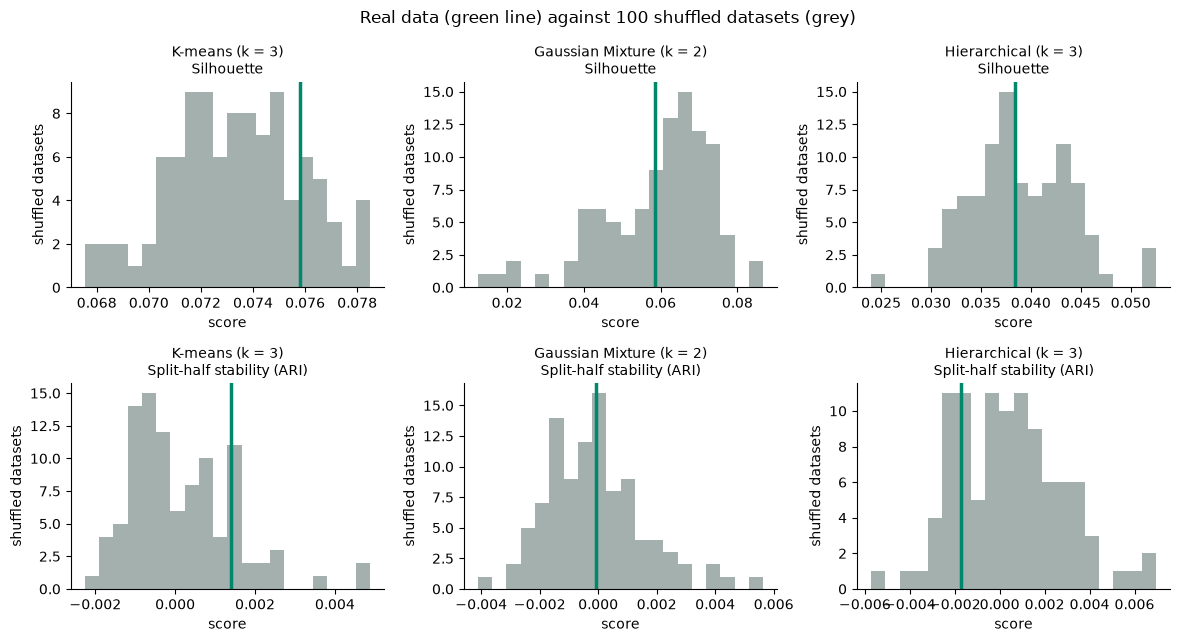

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for j, m in enumerate(MODELS):
    for i, (title, real, shuf) in enumerate([("Silhouette", real_sil, shuf_sil), ("Split-half stability (ARI)", real_stab, shuf_stab)]):
        ax = axes[i, j]
        ax.hist(shuf[m], bins=20, color="#A3B0AD")
        ax.axvline(real[m], color="#00876C", linewidth=2.5)
        ax.set_title(f"{m} (k = {K[m]})\n{title}", fontsize=10)
        ax.set_xlabel("score"); ax.set_ylabel("shuffled datasets")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
fig.suptitle("Real data (green line) against 100 shuffled datasets (grey)", fontsize=12)
plt.tight_layout()
plt.show()

## Verdict
A model counts as **reliable** only if it passes **both** tests after the correction for three models:
1. **Clear groups:** silhouette is at least 0.25 and above shuffled data (`p x 3` below 0.05).
2. **Stable groups:** the split-half ARI is above shuffled data (`p x 3` below 0.05).

In [9]:
verdict = []
for m in MODELS:
    clear = real_sil[m] >= 0.25 and results.loc[m, "silhouette p x 3"] < 0.05
    stable = results.loc[m, "stability p x 3"] < 0.05
    verdict.append({"model": m, "clear groups": "yes" if clear else "no", "stable groups": "yes" if stable else "no",
                    "reliable": "YES" if clear and stable else "no"})
verdict = pd.DataFrame(verdict).set_index("model")
print(verdict.to_string())
print()

off_diag = agree.values[~np.eye(len(MODELS), dtype=bool)]
if (verdict["reliable"] == "YES").any():
    print("Models with reliable groups:", ", ".join(verdict.index[verdict["reliable"] == "YES"]))
else:
    print("No model finds reliable groups. Compare each home with all 500 homes instead of using the groups.")
print(f"Agreement between models: ARI {off_diag.min():.2f} to {off_diag.max():.2f} (1 = identical groups).")

                 clear groups stable groups reliable
model                                               
K-means                    no            no       no
Gaussian Mixture           no            no       no
Hierarchical               no            no       no

No model finds reliable groups. Compare each home with all 500 homes instead of using the groups.
Agreement between models: ARI 0.09 to 0.21 (1 = identical groups).


## Save the results
Writes the two tables to `data/processed/`: `model_comparison.csv` (scores, p-values and verdict) and `model_agreement.csv` (the ARI between each pair of models).

In [10]:
out = results.join(verdict)
out.to_csv(PROCESSED / "model_comparison.csv")
agree.to_csv(PROCESSED / "model_agreement.csv")
print("Saved: data/processed/model_comparison.csv and data/processed/model_agreement.csv")

Saved: data/processed/model_comparison.csv and data/processed/model_agreement.csv


## Result
Same tests, same 100 shuffled datasets, all three models:

| | K-means (k = 3) | Gaussian Mixture (k = 2) | Hierarchical (k = 3) |
|---|---|---|---|
| Silhouette, real data | 0.076 | 0.058 | 0.038 |
| Silhouette, shuffled data (mean) | 0.073 | 0.060 | 0.039 |
| Silhouette p (p x 3) | 0.178 (0.535) | 0.653 (1.000) | 0.495 (1.000) |
| Split-half stability (ARI), real data | 0.001 | -0.000 | -0.002 |
| Split-half stability, shuffled data (mean) | 0.000 | -0.000 | 0.000 |
| Stability p (p x 3) | 0.188 (0.564) | 0.485 (1.000) | 0.792 (1.000) |
| Reliable groups? | No | No | No |

- **Clear groups:** every silhouette is far below 0.25, and the real data scores the same as shuffled data. The homes are no more clustered than random data.
- **Stable groups:** when each home's readings are split in two halves, the groups found in one half do not match the groups found in the other (ARI about 0 for every model). Shuffled data scores the same.
- **Agreement:** the models agree only weakly with each other (ARI 0.09 between K-means and GMM, 0.11 between K-means and Hierarchical, 0.21 between GMM and Hierarchical).

**Conclusion:** none of the three models finds reliable groups of homes, and the result is the same under one common test. This supports the finding in the model notebooks. The groups are descriptive only, and the dashboard compares each home with all 500 homes, appliance by appliance.

**Notes**
- The p-values differ from those in the model notebooks because the tests differ. K-means used a seed-stability test, which is easier to pass (even shuffled data scores 0.3 to 0.6). Here every model gets the stricter split-half test.
- The test is about this dataset, which appears simulated. On a more realistic dataset, run this notebook again and a model that finds real groups should pass both tests.